<a href="https://colab.research.google.com/github/maureljean55/atelier-saint-honore/blob/main/notebooks/entrainement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
clients= pd.read_csv('client_propre.csv')
clients.head()
clients

,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m,montant_total_eur
0,CT80059,BT15,4,4,1468.0,0,0,aucune,en ligne,usa,725.0,1,5872.0
1,CT80578,BT28,80,3,1235.0,1,1,argent,boutique,france,1479.0,1,3705.0
2,CT80256,BT27,43,1,1814.0,0,2,or,boutique,france,2307.0,1,1814.0
3,CT80098,BT16,1,1,1795.0,0,0,or,boutique,italie,1820.0,0,1795.0
4,CT80362,BT31,51,3,2022.0,0,0,argent,boutique,chine,1201.0,1,6066.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
674,CT80211,BT23,78,7,338.0,2,0,argent,en ligne,chine,448.0,1,2366.0
675,CT80502,BT32,48,2,1700.0,0,0,aucune,mixte,chine,1468.0,1,3400.0
676,CT80537,BT32,16,1,2037.0,1,0,aucune,en ligne,chine,1716.0,0,2037.0
677,CT80196,BT33,56,3,2104.0,0,0,argent,en ligne,eau,995.0,1,6312.0


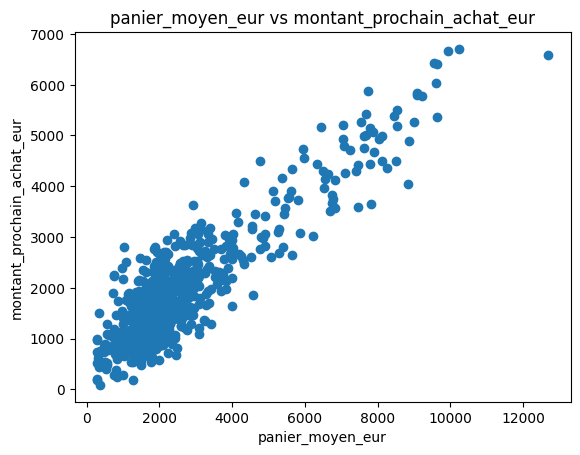

In [30]:
x = clients[["panier_moyen_eur"]]
y = clients["montant_prochain_achat_eur"]

plt.scatter(X, y)
plt.xlabel("panier_moyen_eur")
plt.ylabel("montant_prochain_achat_eur")
plt.title("panier_moyen_eur vs montant_prochain_achat_eur")
plt.show()

In [31]:
y_moyen = [y.mean()] * len(y)
rmse_moyen =round(mean_squared_error(y, y_moyen)**0.5,2)
print("RMSE moyen :", rmse_moyen,"€")

RMSE moyen : 1133.28 €


In [32]:
model = LinearRegression()
model.fit(x,y)
y_moyenPredict = model.predict(x)
print("Coefficient de régression : ", round(model.coef_[0],2))
print("Ordonnée à l'origine : ",round(model.intercept_, 2))

Coefficient de régression :  0.54
Ordonnée à l'origine :  544.17


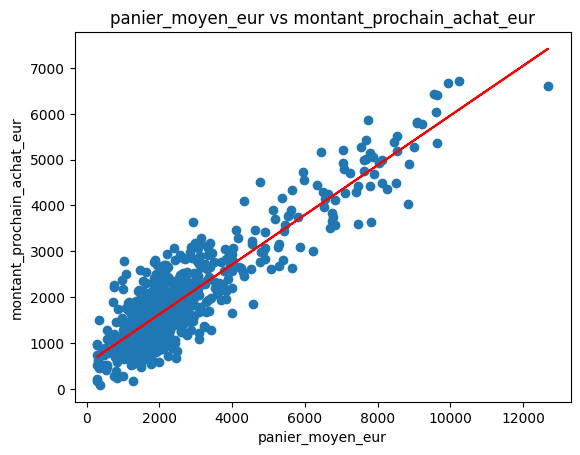

In [33]:
plt.scatter(x,y)
plt.plot(x,y_moyenPredict, color="red")
plt.xlabel("panier_moyen_eur")
plt.ylabel("montant_prochain_achat_eur")
plt.title("panier_moyen_eur vs montant_prochain_achat_eur")
plt.show()

In [35]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)
model.fit(x_train,y_train)
y_predTrain = model.predict(x_train)
rmse_train = round(mean_squared_error(y_train, y_predTrain)**0.5,2)
r2 = round(r2_score(y_train, y_predTrain),2)
print("RMSE train :", rmse_train,"€")
print("R2_score :",r2)

RMSE train : 507.4 €
R2_score : 0.81


In [36]:
y_predTest = model.predict(x_test)
rmse_test = round(mean_squared_error(y_test, y_predTest)**0.5,2)
r2_test = round(r2_score(y_test, y_predTest),2)
print("RMSE test :", rmse_test,"€")
print("R2_score :",r2_test)

RMSE test : 468.9 €
R2_score : 0.8


In [40]:
clients["prochain_achat_prevue"] = model.predict(clients[['panier_moyen_eur']].round(0))
liste = clients[["client_id", "boutique_principale", "panier_moyen_eur", "prochain_achat_prevue","montant_prochain_achat_eur"]]
liste = liste.sort_values("prochain_achat_prevue", ascending=False)

liste.head(10)

,client_id,boutique_principale,panier_moyen_eur,prochain_achat_prevue,montant_prochain_achat_eur
146,CT80672,BT23,12685.0,7364.345175,6594.0
216,CT80289,BT27,10232.0,6045.594524,6708.0
386,CT80530,BT24,9929.0,5882.699519,6667.0
13,CT80142,BT14,9637.0,5725.718195,6408.0
668,CT80584,BT11,9625.0,5719.266907,5366.0
647,CT80494,BT12,9597.0,5704.213903,6038.0
615,CT80107,BT26,9551.0,5679.483969,6425.0
404,CT80465,BT12,9235.0,5509.600069,5772.0
484,CT80540,BT28,9092.0,5432.722229,5792.0
236,CT80699,BT10,9077.0,5424.658119,5829.0
